In [9]:
import pandas as pd

In [10]:
df = pd.read_csv("Hourly total-sales dataset.csv",header=None)

In [11]:
df

,0,1,2,3,4,5
0,2024-12-19 16:00:00.000,2024-12-19,16,3,3.0,0.03
1,2024-12-25 12:00:00.000,2024-12-25,12,1,4.0,6.36
2,2024-12-25 13:00:00.000,2024-12-25,13,6,8.0,15.60
3,2024-12-25 14:00:00.000,2024-12-25,14,2,4.0,35.10
4,2024-12-25 15:00:00.000,2024-12-25,15,4,6.0,15.56
...,...,...,...,...,...,...
8611,2026-07-15 12:00:00.000,2026-07-15,12,16,33.0,64.18
8612,2026-07-15 13:00:00.000,2026-07-15,13,20,67.0,217.43
8613,2026-07-15 14:00:00.000,2026-07-15,14,16,37.0,81.19
8614,2026-07-15 15:00:00.000,2026-07-15,15,20,40.0,119.57


In [12]:
df.columns = [
    'Hours_Start',
    'Sale_Day',
    'Sale_Hour',
    'Transaction_Count',
    'Total_Quantity',
    'Hourly_Sales'
]

In [13]:
df

,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales
0,2024-12-19 16:00:00.000,2024-12-19,16,3,3.0,0.03
1,2024-12-25 12:00:00.000,2024-12-25,12,1,4.0,6.36
2,2024-12-25 13:00:00.000,2024-12-25,13,6,8.0,15.60
3,2024-12-25 14:00:00.000,2024-12-25,14,2,4.0,35.10
4,2024-12-25 15:00:00.000,2024-12-25,15,4,6.0,15.56
...,...,...,...,...,...,...
8611,2026-07-15 12:00:00.000,2026-07-15,12,16,33.0,64.18
8612,2026-07-15 13:00:00.000,2026-07-15,13,20,67.0,217.43
8613,2026-07-15 14:00:00.000,2026-07-15,14,16,37.0,81.19
8614,2026-07-15 15:00:00.000,2026-07-15,15,20,40.0,119.57


In [14]:
df.to_csv("Hourly total-sales dataset.csv", index=False)

In [15]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8616 entries, 0 to 8615
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Hours_Start        8616 non-null   object 
 1   Sale_Day           8616 non-null   object 
 2   Sale_Hour          8616 non-null   int64  
 3   Transaction_Count  8616 non-null   int64  
 4   Total_Quantity     8616 non-null   float64
 5   Hourly_Sales       8616 non-null   float64
dtypes: float64(2), int64(2), object(2)
memory usage: 404.0+ KB


In [16]:
print(df.isnull().sum())

Hours_Start          0
Sale_Day             0
Sale_Hour            0
Transaction_Count    0
Total_Quantity       0
Hourly_Sales         0
dtype: int64


In [17]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [18]:
print(df.describe())

         Sale_Hour  Transaction_Count  Total_Quantity  Hourly_Sales
count  8616.000000        8616.000000     8616.000000   8616.000000
mean     14.357010           7.713556       19.814995     53.068483
std       4.423882           4.516649       12.391791     40.003165
min       6.000000           1.000000        1.000000      0.030000
25%      11.000000           5.000000       11.000000     26.417500
50%      14.000000           7.000000       18.000000     45.115000
75%      18.000000          10.000000       27.000000     70.100000
max      22.000000          37.000000       96.000000    636.510000


In [25]:
print("First date:", df['Sale_Hour'].min())

First date: 6


In [26]:
print("Last date:", df['Sale_Hour'].max())

Last date: 22


In [24]:
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])
df['Sale_Day'] = pd.to_datetime(df['Sale_Day'])


In [27]:
print("First date:", df['Sale_Day'].min())
print("Last date:", df['Sale_Day'].max())
print("Number of days:", df['Sale_Day'].nunique())

First date: 2024-12-19 00:00:00
Last date: 2026-07-15 00:00:00
Number of days: 569


<AxesSubplot:title={'center':'Average Retail Sales by Hour'}, xlabel='Sale_Hour'>

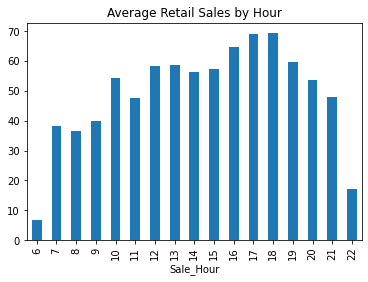

In [23]:
hourly_pattern = (
    df.groupby('Sale_Hour')['Hourly_Sales']
      .mean()
)

hourly_pattern.plot(
    kind='bar',
    title='Average Retail Sales by Hour'
)

In [28]:
df['Day_Name'] = df['Sale_Day'].dt.day_name()
df['Day_of_Week'] = df['Sale_Day'].dt.dayofweek
df['Month'] = df['Sale_Day'].dt.month
df['Month_Name'] = df['Sale_Day'].dt.month_name()
df['Year'] = df['Sale_Day'].dt.year
df['Is_Weekend'] = df['Day_of_Week'].isin([5, 6]).astype(int)

In [32]:
df.head(30)

,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales,Day_Name,Day_of_Week,Month,Month_Name,Year,Is_Weekend
0,2024-12-19 16:00:00,2024-12-19,16,3,3.0,0.03,Thursday,3,12,December,2024,0
1,2024-12-25 12:00:00,2024-12-25,12,1,4.0,6.36,Wednesday,2,12,December,2024,0
2,2024-12-25 13:00:00,2024-12-25,13,6,8.0,15.60,Wednesday,2,12,December,2024,0
3,2024-12-25 14:00:00,2024-12-25,14,2,4.0,35.10,Wednesday,2,12,December,2024,0
4,2024-12-25 15:00:00,2024-12-25,15,4,6.0,15.56,Wednesday,2,12,December,2024,0
5,2024-12-25 16:00:00,2024-12-25,16,1,2.0,2.58,Wednesday,2,12,December,2024,0
6,2024-12-25 17:00:00,2024-12-25,17,2,8.0,22.40,Wednesday,2,12,December,2024,0
7,2024-12-25 18:00:00,2024-12-25,18,1,2.0,3.05,Wednesday,2,12,December,2024,0
8,2024-12-25 19:00:00,2024-12-25,19,4,7.0,34.93,Wednesday,2,12,December,2024,0
9,2024-12-25 20:00:00,2024-12-25,20,2,11.0,46.31,Wednesday,2,12,December,2024,0


<AxesSubplot:title={'center':'Average Hourly Sales by Day of Week'}, xlabel='Day of Week', ylabel='Average Sales (£)'>

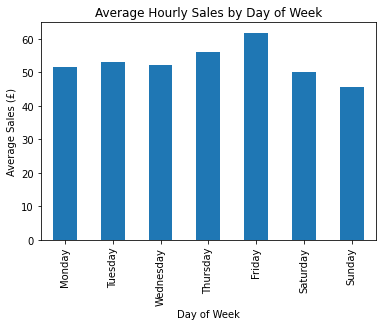

In [33]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_pattern = (
    df.groupby('Day_Name')['Hourly_Sales']
      .mean()
      .reindex(day_order)
)

daily_pattern.plot(
    kind='bar',
    title='Average Hourly Sales by Day of Week',
    xlabel='Day of Week',
    ylabel='Average Sales (£)'
)